# Section 5: the subgame perfect gradient method on the problems of Figure 1.2

Same three problems, data, $f_\star$ and baselines (GD, HBM and NAG with the parameters of Figure 1.2) as in `Section1_experiments.ipynb`, with the subgame perfect gradient method of Section 5.4 on top. Everything is in this notebook.

- **SPGM** (5.22): OGM (5.11) in which, after each query, the weight is raised to the largest value certified by the history, problem (5.21). The upper side is the best value $U_{k+1}=\min_{0\leq i\leq k}\{f(y_i)-\tfrac1{2L}\|\nabla f(y_i)\|^2\}$, attained at the gradient step $\bar x_{k+1}$; the lower side is the maximum of the pieces $q_i$ (5.16), which are lower bounds on $f_\star$ at the minimizers. It does not use $m$, so it runs on the three problems (on (i) and (ii), NAG uses $m$).

**What is plotted.** For SPGM, $f(\bar x_k)-f_\star$, where $\bar x_k$ is the current upper point of the method, which satisfies $f(\bar x_k)-f_\star\leq U_k-f_\star\leq L\|x_0-x_\star\|^2/(2\tilde A_k)$. The output (5.23) with its last step improves the guarantee to $L\|x_0-x_\star\|^2/(2(\tilde A_N+a_N))$ for a horizon $N$ fixed in advance; it is not used here, since all $k$ are plotted.

**Limited memory.** The number of pieces grows with $k$. As at the end of Section 5.4, we keep the last `memory = 10` pieces together with one *aggregate* piece $\sum_i\lambda^\star_iq_i$, the average of the pieces with the optimal weights of the last subproblem. It has the same regularized minimizer and minimal value as the model it replaces, so the a priori weight of OGM remains certified at the next iteration and the realized weights satisfy $\tilde A_k\geq A_k$ (OGM's).

**Cost per iteration.** One gradient and one function value at $y_k$, and a few quadratic programs over the simplex with at most `memory + 2` variables. (The values $f(\bar x_k)$ are only computed for the plot.)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import expit, logsumexp, softmax
from sklearn.datasets import load_diabetes

# Sonar data (UCI). Replace by the path of a local copy if you are offline.
SONAR_FILE = "https://archive.ics.uci.edu/ml/machine-learning-databases/undocumented/connectionist-bench/sonar/sonar.all-data"

## The three methods of Section 1

- GD (1.2): $x_{k+1} = x_k - \alpha\nabla f(x_k)$.
- HBM (1.3): $x_{k+1} = x_k - \alpha\nabla f(x_k) + \beta(x_k - x_{k-1})$, with $x_{-1} = x_0$.
- NAG (1.4): $x_{k+1} = y_k - \alpha\nabla f(y_k)$, $\ y_{k+1} = x_{k+1} + \beta_k(x_{k+1} - x_k)$, with $y_0 = x_0$.

Each function returns the values $f(x_0), f(x_1), \dots, f(x_N)$.

In [2]:
def gd(f, grad, x0, alpha, n_iter):
    x = x0.copy()
    values = [f(x)]
    for k in range(n_iter):
        x = x - alpha * grad(x)
        values.append(f(x))
    return np.array(values)


def hbm(f, grad, x0, alpha, beta, n_iter):
    x, x_prev = x0.copy(), x0.copy()
    values = [f(x)]
    for k in range(n_iter):
        x, x_prev = x - alpha * grad(x) + beta * (x - x_prev), x
        values.append(f(x))
    return np.array(values)


def nag(f, grad, x0, alpha, beta, n_iter):
    # beta is either a number or a function k -> beta_k
    x, y = x0.copy(), x0.copy()
    values = [f(x)]
    for k in range(n_iter):
        x_next = y - alpha * grad(y)
        beta_k = beta(k) if callable(beta) else beta
        y = x_next + beta_k * (x_next - x)
        x = x_next
        values.append(f(x))
    return np.array(values)


def run_methods(f, grad, x0, L, m, n_iter):
    # Parameters of the figure (see the table above).
    if m > 0:
        rL, rm = np.sqrt(L), np.sqrt(m)
        hbm_alpha, hbm_beta = 4 / (rL + rm) ** 2, ((rL - rm) / (rL + rm)) ** 2
        nag_beta = (rL - rm) / (rL + rm)
    else:
        hbm_alpha, hbm_beta = 1 / L, 0.9
        nag_beta = lambda k: k / (k + 3)
    return {
        "GD": gd(f, grad, x0, 1 / L, n_iter),
        "HBM": hbm(f, grad, x0, hbm_alpha, hbm_beta, n_iter),
        "NAG": nag(f, grad, x0, 1 / L, nag_beta, n_iter),
    }

## The subgame perfect gradient method

**The weight.** Problem (5.21) is the convex program (5.25) in $\nu=A\lambda$. By (5.24), it is also the largest $A$ such that
$$\max_{\lambda\in\Delta}\Big\{\textstyle\sum_i\lambda_i\big(q_i(x_0)-U_{k+1}\big)-\tfrac{A}{2L}\big\|\sum_i\lambda_i\nabla f(y_i)\big\|^2\Big\}\geq0,$$
and $\tilde z_{k+1}=x_0-\tfrac{\tilde A_{k+1}}L\sum_i\lambda_i^\star\nabla f(y_i)$. We solve it as for the gradient methods with memory of Section 4.4: for fixed $\lambda$, the largest certified weight is explicit,
$$A(\lambda)=\frac{2L\sum_i\lambda_i\big(q_i(x_0)-U_{k+1}\big)}{\|\sum_i\lambda_i\nabla f(y_i)\|^2},$$
and Newton's method alternates $\lambda\leftarrow$ a maximizer of the quadratic program over the simplex at the current weight (SLSQP, the problems are tiny) and $A\leftarrow A(\lambda)$. It starts from the a priori weights ($\tilde A_k/A_{k+1}$ on the aggregate piece, $a_k/A_{k+1}$ on the new one), which certify OGM's weight $A_{k+1}=\tilde A_k+a_k$, and the weights increase monotonically. Every pair $(\lambda,A(\lambda))$ is itself a certificate, so the quadratic programs need not be solved exactly.

In [3]:
def simplex_qp(b, G, t, lam):
    # A maximizer of b @ lam - t/2 ||G @ lam||^2 over the simplex, warm-started at lam.
    if len(b) == 1:
        return np.ones(1)
    s = max(t * np.max(np.sum(G ** 2, axis=0)), np.max(np.abs(b)), 1e-300)    # scale of the objective
    res = minimize(lambda l: (t / 2 * np.sum((G @ l) ** 2) - b @ l) / s, lam,
                   jac=lambda l: (t * G.T @ (G @ l) - b) / s, method="SLSQP", bounds=[(0, 1)] * len(b),
                   constraints={"type": "eq", "fun": lambda l: np.sum(l) - 1, "jac": lambda l: np.ones_like(l)},
                   options={"ftol": 1e-15, "maxiter": 200})
    lam = np.maximum(res.x, 0)
    return lam / lam.sum()


def largest_weight(b, G, L, lam, n_newton=10):
    # Problem (5.21) by Newton's method from the weights lam, with b_i = q_i(x_0) - U and G = [grad f(y_i)]:
    # largest A such that max_lam {b @ lam - A/(2L) ||G @ lam||^2} >= 0.
    certified = lambda l: 2 * L * (b @ l) / np.sum((G @ l) ** 2)     # largest weight certified by the weights l
    A = certified(lam)
    for _ in range(n_newton):
        lam_new = simplex_qp(b, G, A / L, lam)
        A_new = certified(lam_new)
        if not A_new > A * (1 + 1e-9):
            break
        A, lam = A_new, lam_new
    return A, lam


def spgm(f, grad, x0, L, n_iter, memory=10):
    # SPGM (5.22). Pieces q_i (5.16) stored as (q_i(x_0), grad f(y_i)); column 0 is the aggregate piece.
    # Returns f(xbar_0), ..., f(xbar_N) and the realized weights.
    xbar, z, A, U = x0.copy(), x0.copy(), 0.0, np.inf
    c, G = np.zeros(0), np.zeros((len(x0), 0))
    f_xbar = f(x0)
    values, weights = [f_xbar], [A]
    for k in range(n_iter):
        a = 1 + np.sqrt(1 + 2 * A)
        A_next = A + a                                                   # a priori weight (OGM)
        y = A / A_next * xbar + a / A_next * z
        g, f_y = grad(y), f(y)
        x = y - g / L
        if f_y - g @ g / (2 * L) < U:                                    # best upper bound U_{k+1}, attained at xbar_{k+1}
            U, xbar = f_y - g @ g / (2 * L), x
            f_xbar = f(xbar)                                             # only for the plot
        c = np.append(c, f_y + g @ (x0 - y) + g @ g / (2 * L))           # new piece q_k
        G = np.column_stack([G, g])
        lam_prior = np.zeros(len(c))
        lam_prior[0] += A / A_next
        lam_prior[-1] += a / A_next
        A, lam = largest_weight(c - U, G, L, lam_prior)
        if not A >= A_next:                                              # floating-point safeguard
            A, lam = A_next, lam_prior
        z = x0 - A / L * G @ lam
        keep = slice(max(1, len(c) - memory), len(c))                    # last pieces (column 0 is the aggregate)
        c, G = np.append(c @ lam, c[keep]), np.column_stack([G @ lam, G[:, keep]])
        values.append(f_xbar)
        weights.append(A)
    return np.array(values), np.array(weights)


def ogm_weights(n_iter):
    # a priori weights of OGM (5.11), a_k^2 = 2 A_{k+1}
    A = [0.0]
    for k in range(n_iter):
        A.append(A[-1] + 1 + np.sqrt(1 + 2 * A[-1]))
    return np.array(A)


def report(label, gap, weights, prior_weights, numerator, k=100):
    # realized vs a priori weight at iteration k, and the certified bound numerator / weight against the actual gap
    bound = numerator / weights[1:]
    valid = np.all(gap[1:] <= bound * (1 + 1e-9) + 1e-15)
    print(f"  {label}: at k = {k}, weight {weights[k]:.2e} (a priori {prior_weights[k]:.2e}), "
          f"bound {bound[k - 1]:.1e} >= f(xbar_k) - f_star = {gap[k]:.1e};  bound valid for all k: {valid}")

## Computing $f_\star$

Closed form for least squares. For the two other problems $d$ is small, so a trust-region Newton method (exact Hessians) reaches $f_\star$ to machine precision. We keep $x_\star$ to evaluate the bound $f(x_k)-f_\star\leq L\|x_0-x_\star\|^2/(2\tilde A_k)$ certified by SPGM.

In [4]:
def solve_with_newton(f, grad, hess, x0):
    res = minimize(f, x0, jac=grad, hess=hess, method="trust-exact", options={"gtol": 1e-13, "maxiter": 1000})
    print(f"  Newton: {res.nit} iterations, |grad f(x*)| = {np.linalg.norm(grad(res.x)):.1e}")
    return res.x

## Data

In [5]:
def standardize(X):
    return (X - X.mean(axis=0)) / X.std(axis=0)


def add_intercept(Z):
    return np.hstack([Z, np.ones((Z.shape[0], 1))])


# Diabetes (Efron, Hastie, Johnstone and Tibshirani 2004): raw data shipped with scikit-learn
diabetes = load_diabetes(scaled=False)
A_diabetes = add_intercept(standardize(diabetes.data))
b_diabetes = standardize(diabetes.target)

# Sonar (Gorman and Sejnowski 1988): 60 features, label "M" (mine) or "R" (rock)
sonar = pd.read_csv(SONAR_FILE, header=None)
A_sonar = add_intercept(standardize(sonar.iloc[:, :60].to_numpy(dtype=float)))
y_sonar = np.where(sonar.iloc[:, 60] == "M", 1.0, -1.0)

print("diabetes:", A_diabetes.shape, "  sonar:", A_sonar.shape)

diabetes: (442, 11)   sonar: (208, 61)


## (i) Least squares on diabetes

$f(x) = \frac{1}{2n}\|Ax-b\|^2$, with $L = \lambda_{\max}(A^\top A)/n$ and $m = \lambda_{\min}(A^\top A)/n$.

In [6]:
def make_least_squares(A, b):
    n = A.shape[0]
    def f(x):
        return np.sum((A @ x - b) ** 2) / (2 * n)
    def grad(x):
        return A.T @ (A @ x - b) / n
    return f, grad


A, b = A_diabetes, b_diabetes
n, d = A.shape
f, grad = make_least_squares(A, b)

eigenvalues = np.linalg.eigvalsh(A.T @ A / n)
L, m = eigenvalues[-1], eigenvalues[0]
x_star = np.linalg.lstsq(A, b, rcond=None)[0]
f_star = f(x_star)
print(f"L = {L:.3g}, m = {m:.3g}, kappa = {L / m:.0f}, f_star = {f_star:.6f}")

N = 1000
values = run_methods(f, grad, np.zeros(d), L, m, n_iter=N)
values["SPGM"], weights = spgm(f, grad, np.zeros(d), L, n_iter=N)
report("SPGM", values["SPGM"] - f_star, weights, ogm_weights(N), L * x_star @ x_star / 2)
gaps_ls = {name: v - f_star for name, v in values.items()}

L = 4.02, m = 0.00856, kappa = 470, f_star = 0.241126


  SPGM: at k = 100, weight 4.66e+05 (a priori 5.30e+03), bound 3.1e-06 >= f(xbar_k) - f_star = 4.7e-08;  bound valid for all k: True


## (ii) $\ell_2$-regularized logistic regression on sonar

$f(x) = \frac1n\sum_i \log(1+e^{-y_i\langle a_i,x\rangle}) + \frac\lambda2\|x\|^2$ with $\lambda = 1/n$. Since $\sigma' \leq 1/4$, the Hessian is at most $\frac{1}{4n}A^\top A + \lambda I$, which gives $L = \lambda_{\max}(A^\top A)/(4n) + \lambda$; and $m = \lambda$.

In [7]:
def make_logistic(A, y, lam):
    n, d = A.shape
    def f(x):
        return np.mean(np.logaddexp(0, -y * (A @ x))) + lam / 2 * x @ x
    def grad(x):
        return -A.T @ (y * expit(-y * (A @ x))) / n + lam * x
    def hess(x):
        s = expit(A @ x)
        return A.T @ (A * (s * (1 - s))[:, None]) / n + lam * np.eye(d)
    return f, grad, hess


A, y = A_sonar, y_sonar
n, d = A.shape
lam = 1 / n
f, grad, hess = make_logistic(A, y, lam)

L = np.linalg.eigvalsh(A.T @ A)[-1] / (4 * n) + lam
m = lam
x_star = solve_with_newton(f, grad, hess, np.zeros(d))
f_star = f(x_star)
print(f"L = {L:.3g}, m = {m:.3g}, kappa = {L / m:.0f}, f_star = {f_star:.6f}")

N = 1000
values = run_methods(f, grad, np.zeros(d), L, m, n_iter=N)
values["SPGM"], weights = spgm(f, grad, np.zeros(d), L, n_iter=N)
report("SPGM", values["SPGM"] - f_star, weights, ogm_weights(N), L * x_star @ x_star / 2)
gaps_logistic = {name: v - f_star for name, v in values.items()}

  Newton: 7 iterations, |grad f(x*)| = 1.4e-11
L = 3.06, m = 0.00481, kappa = 636, f_star = 0.262018


  SPGM: at k = 100, weight 4.61e+05 (a priori 5.30e+03), bound 6.2e-05 >= f(xbar_k) - f_star = 3.0e-06;  bound valid for all k: True


## (iii) Smoothed $\ell_\infty$ regression on diabetes

$\max_i |\langle a_i,x\rangle - b_i|$ is the maximum of the $2n$ affine functions $\ell(x) = \pm(Ax-b)$, smoothed into $f_\tau(x) = \tau\log\sum_{i=1}^{2n} e^{\ell_i(x)/\tau}$ (error at most $\tau\log(2n)$). The Hessian is $\frac1\tau \tilde A^\top(\mathrm{Diag}(p)-pp^\top)\tilde A$ with $p = \mathrm{softmax}(\ell/\tau)$ and $\tilde A = [A; -A]$, so $L = \max_i\|a_i\|^2/\tau$ and $m = 0$.

In [8]:
def make_smoothed_linf(A, b, tau):
    A2, b2 = np.vstack([A, -A]), np.concatenate([b, -b])    # the 2n pieces
    def f(x):
        return tau * logsumexp((A2 @ x - b2) / tau)
    def grad(x):
        return A2.T @ softmax((A2 @ x - b2) / tau)
    def hess(x):
        p = softmax((A2 @ x - b2) / tau)
        Ap = A2.T @ p
        return (A2.T @ (A2 * p[:, None]) - np.outer(Ap, Ap)) / tau
    return f, grad, hess


A, b = A_diabetes, b_diabetes
n, d = A.shape
tau = 0.02
f, grad, hess = make_smoothed_linf(A, b, tau)

L = np.max(np.sum(A ** 2, axis=1)) / tau
m = 0
x_star = solve_with_newton(f, grad, hess, np.zeros(d))
f_star = f(x_star)
print(f"L = {L:.4g}, m = 0, smoothing error tau log(2n) = {tau * np.log(2 * n):.3f}, f_star = {f_star:.6f}")

N = 3000
values = run_methods(f, grad, np.zeros(d), L, m, n_iter=N)
values["SPGM"], weights = spgm(f, grad, np.zeros(d), L, n_iter=N)
report("SPGM", values["SPGM"] - f_star, weights, ogm_weights(N), L * x_star @ x_star / 2, k=1000)
gaps_linf = {name: v - f_star for name, v in values.items()}

  Newton: 20 iterations, |grad f(x*)| = 3.0e-12
L = 2489, m = 0, smoothing error tau log(2n) = 0.136, f_star = 1.677366


  SPGM: at k = 1000, weight 2.42e+10 (a priori 5.04e+05), bound 7.4e-09 >= f(xbar_k) - f_star = 3.7e-11;  bound valid for all k: True


## Figure

Gaps below $10^{-16}$ (machine precision, possibly negative) are drawn at $10^{-16}$. On (i) and (ii), NAG uses $m$ (constant momentum) while SPGM does not.

The realized weights depend on which pieces are active in the subproblems, so the trajectory of SPGM is sensitive to small perturbations: the details of its curve in the last decades change with the memory size or with rounding, not its overall behavior.

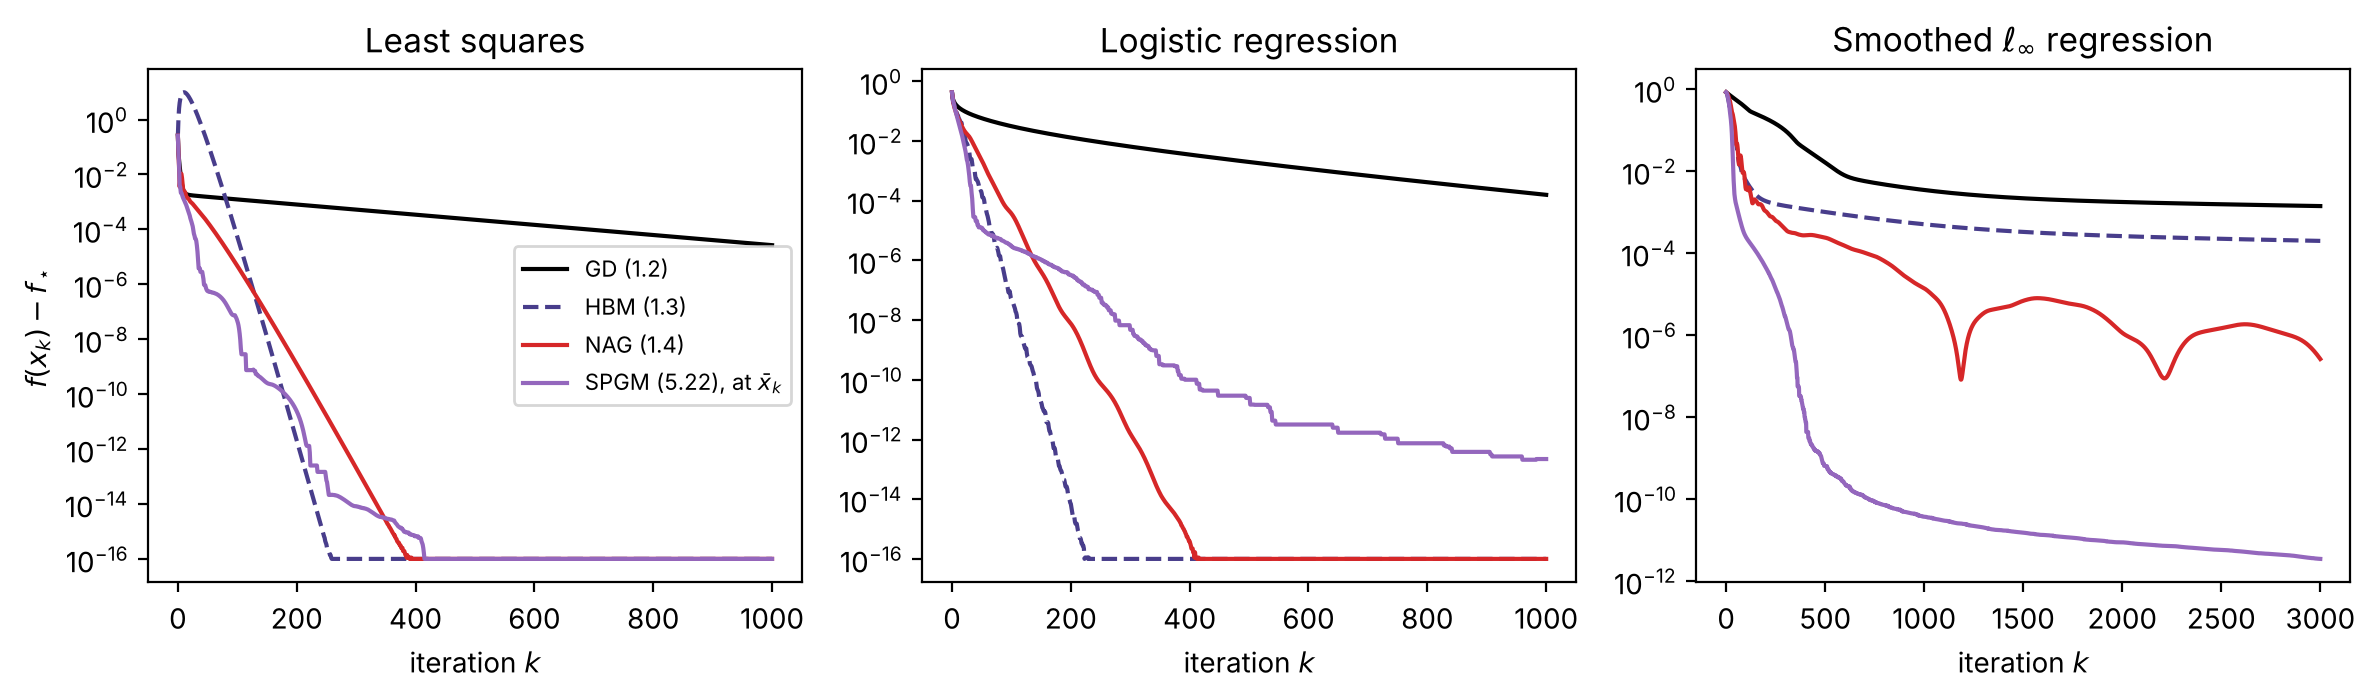

In [9]:
panels = {
    "Least squares": gaps_ls,
    "Logistic regression": gaps_logistic,
    r"Smoothed $\ell_\infty$ regression": gaps_linf,
}
styles = {
    "GD": dict(color="black", label="GD (1.2)"),
    "HBM": dict(color="darkslateblue", linestyle="--", label="HBM (1.3)"),
    "NAG": dict(color="tab:red", label="NAG (1.4)"),
    "SPGM": dict(color="tab:purple", label=r"SPGM (5.22), at $\bar x_k$"),
}

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (title, gaps) in zip(axes, panels.items()):
    for name, gap in gaps.items():
        ax.semilogy(np.maximum(gap, 1e-16), **styles[name])
    ax.set_title(title)
    ax.set_xlabel("iteration $k$")
axes[0].set_ylabel(r"$f(x_k) - f_\star$")
axes[0].legend(fontsize=8)
fig.tight_layout()
# fig.savefig("fig_section5_experiments.pdf")
plt.show()

## Save into .dat

In [10]:
import os

DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)

files = {
    "section5_least_squares_diabetes": gaps_ls,
    "section5_logistic_sonar": gaps_logistic,
    "section5_logsumexp_diabetes": gaps_linf,
}
columns = {"GD": "gd_f", "HBM": "hbm_f", "NAG": "nag_f", "SPGM": "spgm_f"}

for name, gaps in files.items():
    k = np.arange(len(gaps["GD"]))
    header = " ".join(["k"] + [columns[method] for method in gaps])
    fmt = ["%d"] + ["%.6e"] * len(gaps)
    table = np.column_stack([k] + [np.maximum(gap, 1e-16) for gap in gaps.values()])
    np.savetxt(f"{DATA_DIR}/{name}.dat", table, header=header, fmt=fmt, comments="")

    # thin copy: every iteration up to k = 50, then about 300 points, and the last one
    step = max(1, len(k) // 300)
    keep = (k <= 50) | (k % step == 0) | (k == k[-1])
    np.savetxt(f"{DATA_DIR}/{name}_thin.dat", table[keep], header=header, fmt=fmt, comments="")
    print(f"{DATA_DIR}/{name}.dat: {len(k)} rows, thin copy: {keep.sum()} rows")

data/section5_least_squares_diabetes.dat: 1001 rows, thin copy: 369 rows
data/section5_logistic_sonar.dat: 1001 rows, thin copy: 369 rows
data/section5_logsumexp_diabetes.dat: 3001 rows, thin copy: 346 rows
